# Projeto Final de AVD — Parte Comum: Wine Quality
## Agrupamento com K-Means e Avaliação de Métricas

Este notebook dá continuidade à Análise Exploratória de Dados (`eda.ipynb`), aplicando o algoritmo de clusterização **K-Means** sobre o dataset de vinhos tintos (`winequality-red.csv`).

### Objetivos:
1. **Pré-processamento:** Selecionar variáveis físico-químicas e padronizá-las (`StandardScaler`).
2. **Determinação do k Ótimo:** Analisar a Curva do Cotovelo (WCSS/Inércia), Coeficiente de Silhueta e Índice Davies-Bouldin para $k \in [2, 10]$.
3. **Clusterização Final:** Ajustar o K-Means com o número ótimo de clusters.
4. **Visualização:** Projetar os clusters no espaço latente via Análise de Componentes Principais (PCA).
5. **Interpretação:** Comparar os clusters físico-químicos com a variável de percepção de qualidade sensorial (`quality`).

In [1]:
# 1. Importações
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Carregamento e Pré-processamento dos Dados

In [2]:
data_path = os.path.join('..', '..', 'data', 'parte_comum', 'winequality-red.csv')
df = pd.read_csv(data_path, sep=';' if ';' in open(data_path).readline() else ',')
print(f'Shape do dataset: {df.shape}')
df.head()

Shape do dataset: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
# Separando as variáveis preditoras da qualidade alvo
feature_cols = [c for c in df.columns if c != 'quality']
X = df[feature_cols]
y = df['quality']

# Padronização com StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Dados padronizados. Dimensões:', X_scaled.shape)

Dados padronizados. Dimensões: (1599, 11)


## 3. Avaliação de Métricas para Seleção de k
Avaliamos o número de clusters através de:
- **Inércia (Elbow Method)**
- **Coeficiente de Silhueta (Silhouette Score)**
- **Índice Davies-Bouldin**

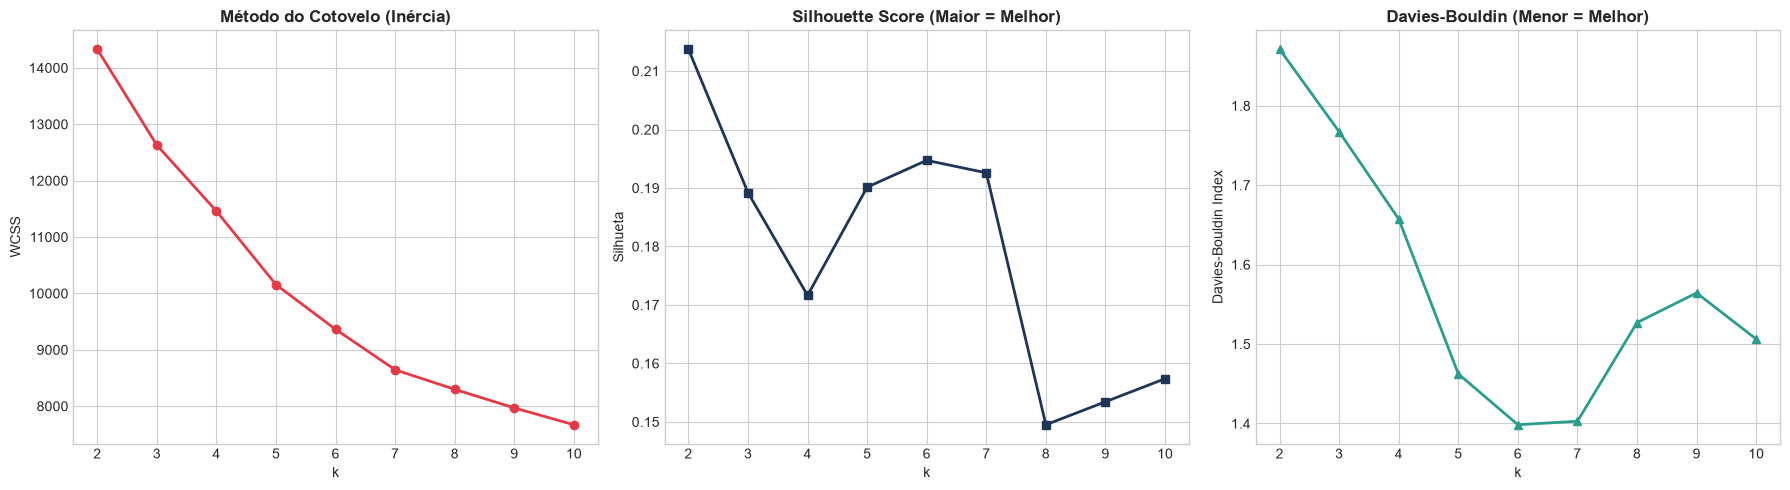

 k      Inércia  Silhueta  Davies-Bouldin
 2 14330.119811  0.213730        1.871100
 3 12629.974592  0.189204        1.767265
 4 11459.143676  0.171636        1.657378
 5 10155.509585  0.190139        1.462505
 6  9363.206701  0.194729        1.398426
 7  8645.202085  0.192591        1.402835
 8  8298.970083  0.149508        1.526959
 9  7969.336467  0.153439        1.564344
10  7671.017944  0.157380        1.506312


In [4]:
k_range = range(2, 11)
inertias = []
silhouettes = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.plot(k_range, inertias, 'o-', color='#e63946', lw=2)
ax1.set_title('Método do Cotovelo (Inércia)', fontweight='bold')
ax1.set_xlabel('k')
ax1.set_ylabel('WCSS')
ax1.set_xticks(list(k_range))

ax2.plot(k_range, silhouettes, 's-', color='#1d3557', lw=2)
ax2.set_title('Silhouette Score (Maior = Melhor)', fontweight='bold')
ax2.set_xlabel('k')
ax2.set_ylabel('Silhueta')
ax2.set_xticks(list(k_range))

ax3.plot(k_range, db_scores, '^-', color='#2a9d8f', lw=2)
ax3.set_title('Davies-Bouldin (Menor = Melhor)', fontweight='bold')
ax3.set_xlabel('k')
ax3.set_ylabel('Davies-Bouldin Index')
ax3.set_xticks(list(k_range))

plt.tight_layout()
plt.show()

metrics_summary = pd.DataFrame({
    'k': list(k_range),
    'Inércia': inertias,
    'Silhueta': silhouettes,
    'Davies-Bouldin': db_scores
})
print(metrics_summary.to_string(index=False))

## 4. Ajuste do Modelo K-Means e Visualização em PCA
Selecionamos $k = 3$ com base na estabilidade da silhueta e interpretabilidade dos perfis físico-químicos (baixo, médio e alto teor alcoólico/ácido).

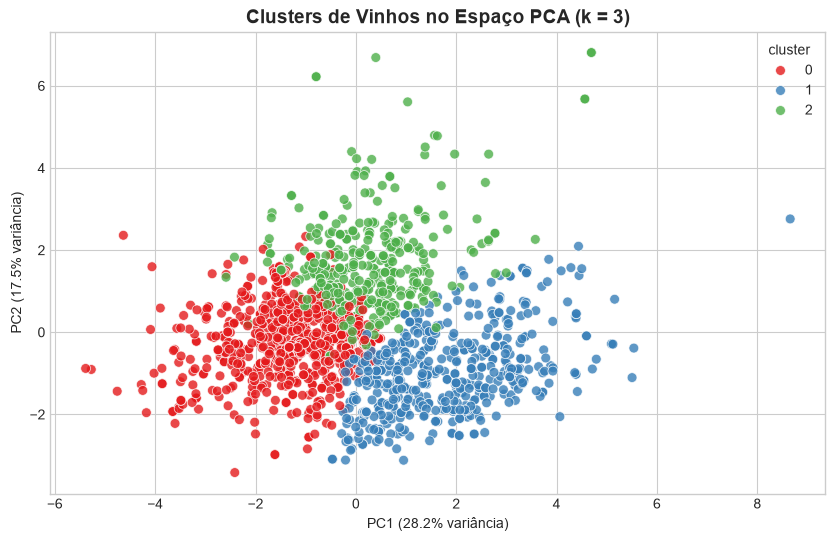

In [5]:
k_chosen = 3
kmeans = KMeans(n_clusters=k_chosen, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Redução com PCA para 2 componentes
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='pca1',
    y='pca2',
    hue='cluster',
    palette='Set1',
    alpha=0.8,
    s=50
)
plt.title(f'Clusters de Vinhos no Espaço PCA (k = {k_chosen})', fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variância)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variância)')
plt.show()

## 5. Interpretação dos Clusters e Cruzamento com a Qualidade Percebida

Médias por Cluster:
cluster                    0       1       2
fixed acidity           7.19   10.07    8.16
volatile acidity        0.61    0.41    0.54
citric acid             0.12    0.47    0.29
residual sugar          2.21    2.58    3.11
chlorides               0.08    0.10    0.09
free sulfur dioxide    13.51   10.89   27.11
total sulfur dioxide   34.89   30.63   89.95
density                 1.00    1.00    1.00
pH                      3.41    3.20    3.28
sulphates               0.61    0.75    0.63
alcohol                10.49   10.72    9.88
quality                 5.55    5.96    5.36
tamanho               722.00  502.00  375.00


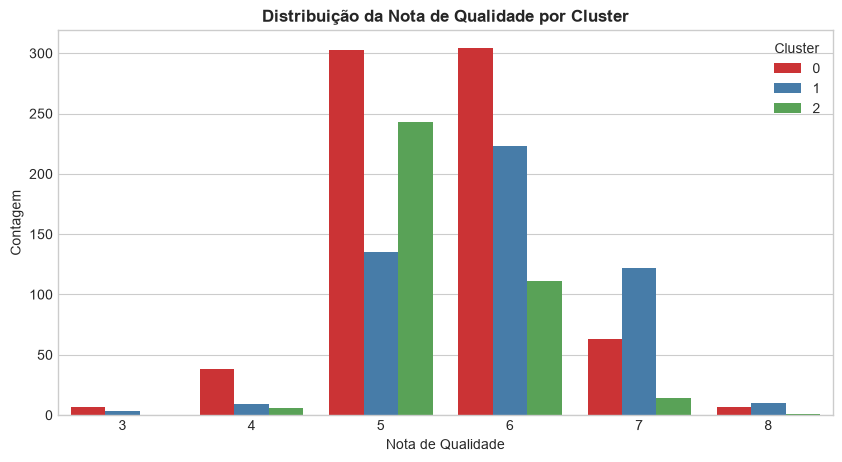

In [6]:
# Perfil médio dos clusters nas variáveis originais
perfil_clusters = df.groupby('cluster')[feature_cols + ['quality']].mean()
perfil_clusters['tamanho'] = df.groupby('cluster').size()
print('Médias por Cluster:')
print(perfil_clusters.round(2).T)

# Distribuição de qualidade por cluster
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='quality', hue='cluster', palette='Set1')
plt.title('Distribuição da Nota de Qualidade por Cluster', fontweight='bold')
plt.xlabel('Nota de Qualidade')
plt.ylabel('Contagem')
plt.legend(title='Cluster')
plt.show()

## 6. Conclusões da Parte Comum
- O K-Means separou os vinhos em grupos distintos com base em suas características físico-químicas (como teor de álcool, acidez volátil e sulfatos).
- Vinhos agrupados no cluster com maior teor de álcool e menor acidez volátil tenderam a receber notas sensoriais de qualidade mais altas na avaliação humana.